In [16]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
from IEEE.prepare_IEEE import process_all_IEEE_files, load_IEEE_labels


In [18]:
WINDOW_SIZE = 1024
OVERLAP = int(WINDOW_SIZE/2)
MAX_WINDOWS = 200  # windows kept per signal per recording (None keeps all 1954, which makes very large DataFrames)

all_processed_windows_a, all_processed_windows_b, all_processed_windows_c = process_all_IEEE_files(WINDOW_SIZE, OVERLAP, MAX_WINDOWS)

print(f"Total processed windows for 'isa': {len(all_processed_windows_a)}")
print(f"Total processed windows for 'isb': {len(all_processed_windows_b)}")
print(f"Total processed windows for 'isc': {len(all_processed_windows_c)}")

Found 400 files


Processing files: 100%|██████████| 400/400 [00:01<00:00, 349.63it/s]

Total processed windows for 'isa': 2400
Total processed windows for 'isb': 2400
Total processed windows for 'isc': 2400


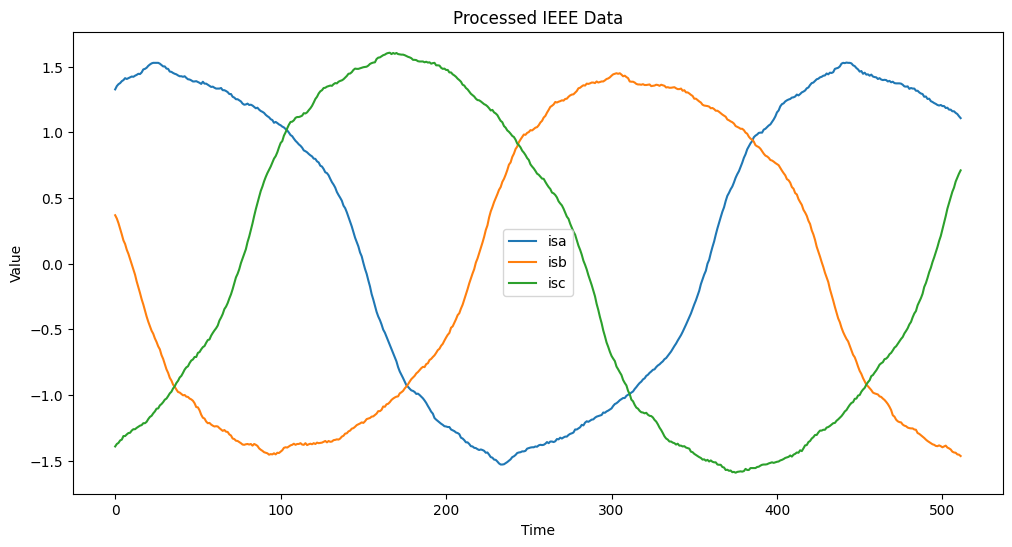

In [19]:
plt.figure(figsize=(12, 6))
plt.plot(all_processed_windows_a[0]['data'], label='isa')
plt.plot(all_processed_windows_b[0]['data'], label='isb')
plt.plot(all_processed_windows_c[0]['data'], label='isc')
plt.xlabel('Time')
plt.ylabel('Value')
plt.title('Processed IEEE Data')
plt.legend()
plt.show()

In [20]:
def windows_to_dataframe(processed_windows):
    rows = []

    for window in processed_windows:
        row = window["metadata"].copy()

        for i, value in enumerate(window["data"]):
            row[f"sample_{i}"] = value

        rows.append(row)

    return pd.DataFrame(rows)

In [21]:
# Step 2: Convert windows to DataFrames
labels = load_IEEE_labels()[["file_name", "torque"]]

df_a = windows_to_dataframe(all_processed_windows_a)
df_b = windows_to_dataframe(all_processed_windows_b)
df_c = windows_to_dataframe(all_processed_windows_c)

for df in (df_a, df_b, df_c):
    df["torque"] = df["file_name"].str.extract(r"torque(\d+)", expand=False).astype(int)

In [22]:
df_a

,file_name,window_num,window_size,overlap,signal_type,sample_0,sample_1,sample_2,sample_3,sample_4,...,sample_503,sample_504,sample_505,sample_506,sample_507,sample_508,sample_509,sample_510,sample_511,torque
0,r1b_torque05_01.csv,0,1024,512,isa,1.327084,1.352083,1.366667,1.375000,1.389584,...,1.187500,1.172917,1.172917,1.160417,1.160417,1.147917,1.139584,1.122917,1.108334,5
1,r1b_torque05_01.csv,1,1024,512,isa,-1.383333,-1.379167,-1.381250,-1.379166,-1.370834,...,-0.502083,-0.487500,-0.452083,-0.427083,-0.389583,-0.360417,-0.331250,-0.304167,-0.268750,5
2,r1b_torque05_01.csv,2,1024,512,isa,1.106250,1.091667,1.089583,1.072916,1.056250,...,-1.027083,-1.035417,-1.029167,-1.045833,-1.045834,-1.054167,-1.062500,-1.079166,-1.089583,5
3,r1b_torque05_01.csv,3,1024,512,isa,-0.239583,-0.195833,-0.158333,-0.112500,-0.077083,...,1.487500,1.493750,1.514583,1.520833,1.518750,1.533333,1.531250,1.531250,1.535417,5
4,r1b_torque05_01.csv,4,1024,512,isa,-1.110417,-1.116667,-1.137500,-1.168750,-1.187500,...,-1.293750,-1.285417,-1.266666,-1.272917,-1.260417,-1.254167,-1.235417,-1.222917,-1.222917,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2395,rs_torque40_10.csv,1,1024,512,isa,-2.262500,-2.256250,-2.266666,-2.262500,-2.250000,...,0.125000,0.166667,0.202083,0.243750,0.285417,0.337500,0.366667,0.420833,0.452083,40
2396,rs_torque40_10.csv,2,1024,512,isa,1.029167,1.006250,0.983333,0.964583,0.931250,...,-1.697917,-1.725000,-1.760417,-1.795834,-1.839584,-1.883333,-1.933334,-1.972917,-2.002083,40
2397,rs_torque40_10.csv,3,1024,512,isa,0.493750,0.533333,0.570833,0.597917,0.629167,...,2.285417,2.264583,2.260416,2.252083,2.254167,2.233333,2.229167,2.233333,2.233334,40
2398,rs_torque40_10.csv,4,1024,512,isa,-2.050000,-2.085417,-2.118750,-2.154167,-2.175000,...,-1.820833,-1.783333,-1.743750,-1.710417,-1.662500,-1.618750,-1.579166,-1.550000,-1.510417,40
